## Imports and Setup

In [ ]:
!pip install arch --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 15.8 MB/s eta 0:00:00


In [ ]:
# ============================================
#   GARCH(1,1) Monte Carlo Leveraged vs Unleveraged
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model

%matplotlib inline


## Monte Carlo Simulation
# Features
Daily upside skew

annual drift

GARCH(1,1) volatility



In [ ]:
def monte_carlo_garch_leverage(
    n_sims=2000,
    n_days=252,
    leverage=3.0,
    initial_price=100.0,
    annual_drift=0.10,
    ann_vol=0.19,
    alpha=0.05, beta=0.90,
    use_student_t=True,
    df_t=8,                  # slightly higher df = fewer blow-ups
    include_risk_free=False,
    r_f=0.02,
    clip_min=-0.25,          # daily return floor  (-25%)
    clip_max=0.15,           # daily return ceiling (+15%)
    vol_cap_mult=5.0         # cap σₜ at 5× baseline daily σ
):
    """
    Stable Monte Carlo GARCH(1,1) simulation with clipping and volatility cap.
    Returns risk metrics (Sharpe, Sortino, Calmar, MDD).
    """

    # --- Daily parameters ---
    dt = 1 / 252
    drift_daily = annual_drift * dt
    base_sigma = ann_vol * np.sqrt(dt)
    omega = base_sigma**2 * (1 - alpha - beta)

    # --- Allocate arrays ---
    eps = np.zeros((n_sims, n_days))
    sigma = np.zeros((n_sims, n_days))
    ret = np.zeros((n_sims, n_days))
    sigma[:, 0] = np.sqrt(omega / (1 - alpha - beta))

    # --- GARCH evolution ---
    for t in range(1, n_days):
        z = np.random.standard_t(df_t, size=n_sims) if use_student_t else np.random.randn(n_sims)
        eps[:, t-1] = sigma[:, t-1] * z
        sigma[:, t] = np.sqrt(omega + alpha * eps[:, t-1]**2 + beta * sigma[:, t-1]**2)
        # Cap volatility
        sigma[:, t] = np.minimum(sigma[:, t], vol_cap_mult * base_sigma)
        ret[:, t] = drift_daily + sigma[:, t] * z

    if include_risk_free:
        ret -= r_f / 252

    # --- Clip returns to realistic bounds ---
    ret = np.clip(ret, clip_min, clip_max)

    # --- Simulate price paths ---
    unlev_paths = initial_price * np.cumprod(1 + ret, axis=1)
    lev_paths   = initial_price * np.cumprod(1 + leverage * ret, axis=1)

    # --- Helper for metrics ---
    def metrics(paths):
        daily_r = (paths[:,1:] - paths[:,:-1]) / paths[:,:-1]
        mean_d, std_d = np.mean(daily_r), np.std(daily_r)
        downside = np.std(daily_r[daily_r < 0])
        ann_ret = (1 + mean_d)**252 - 1
        sharpe  = (mean_d*252 - r_f) / (std_d*np.sqrt(252))
        sortino = (mean_d*252 - r_f) / (downside*np.sqrt(252))
        mdd = np.mean([np.min((p - np.maximum.accumulate(p))/np.maximum.accumulate(p)) for p in paths])
        calmar = ann_ret / abs(mdd) if mdd != 0 else np.nan
        return ann_ret, std_d, sharpe, sortino, calmar, mdd

    un_m = metrics(unlev_paths)
    lv_m = metrics(lev_paths)

    summary = pd.DataFrame({
        'Annual Return':[un_m[0], lv_m[0]],
        'Std Dev':[un_m[1], lv_m[1]],
        'Sharpe':[un_m[2], lv_m[2]],
        'Sortino':[un_m[3], lv_m[3]],
        'Calmar':[un_m[4], lv_m[4]],
        'Max Drawdown':[un_m[5], lv_m[5]]
    }, index=['Unleveraged', f'{leverage}× Leveraged'])

    # --- Plot mean paths ---
    plt.figure(figsize=(10,6))
    plt.plot(np.mean(unlev_paths, axis=0), label='Unleveraged', color='blue')
    plt.plot(np.mean(lev_paths, axis=0), label=f'{leverage}× Leveraged', color='red')
    plt.title(f"Stable GARCH(1,1) Monte Carlo – α={alpha:.2f}, β={beta:.2f}, df={df_t}")
    plt.xlabel('Days'); plt.ylabel('Portfolio Value'); plt.legend(); plt.grid(True); plt.show()

    print("\n=== Risk-Adjusted Summary ===")
    print(summary.round(4))
    return summary, unlev_paths, lev_paths, sigma


## Main

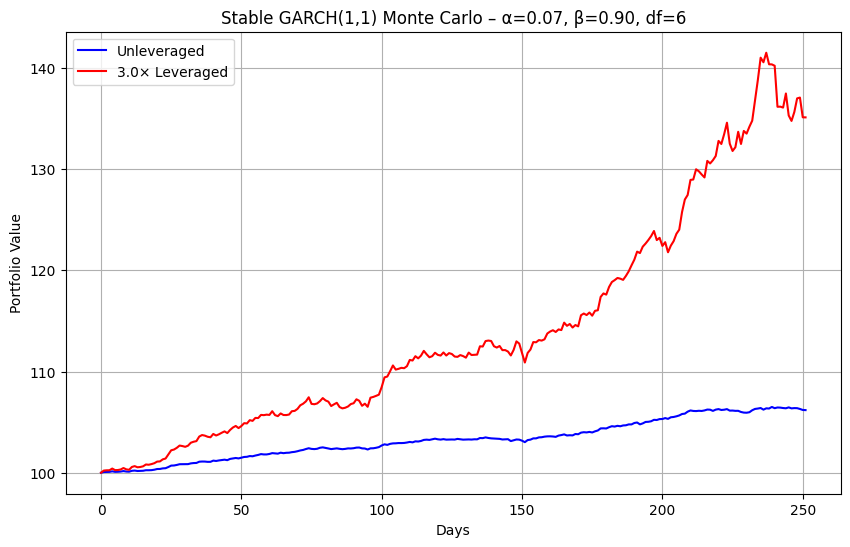


=== Risk-Adjusted Summary ===
                Annual Return  Std Dev  Sharpe  Sortino  Calmar  Max Drawdown
Unleveraged            0.0536   0.0329  0.0617   0.0770  0.1263       -0.4244
3.0× Leveraged         0.1695   0.0987  0.0872   0.1089  0.2105       -0.8054


In [ ]:
summary, unlev_paths, lev_paths, sigma = monte_carlo_garch_leverage(
    n_sims=3000,
    n_days=252,
    leverage=3.0,
    initial_price=100.0,
    annual_drift=0.10,
    ann_vol=0.19,
    alpha=0.07,
    beta=0.90,
    use_student_t=True,
    df_t=6,
    include_risk_free=False
)


## Volatility & Dispersion Visualization

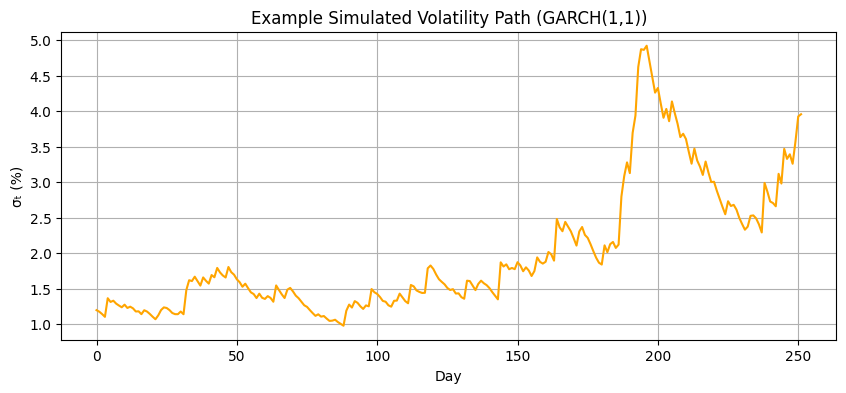

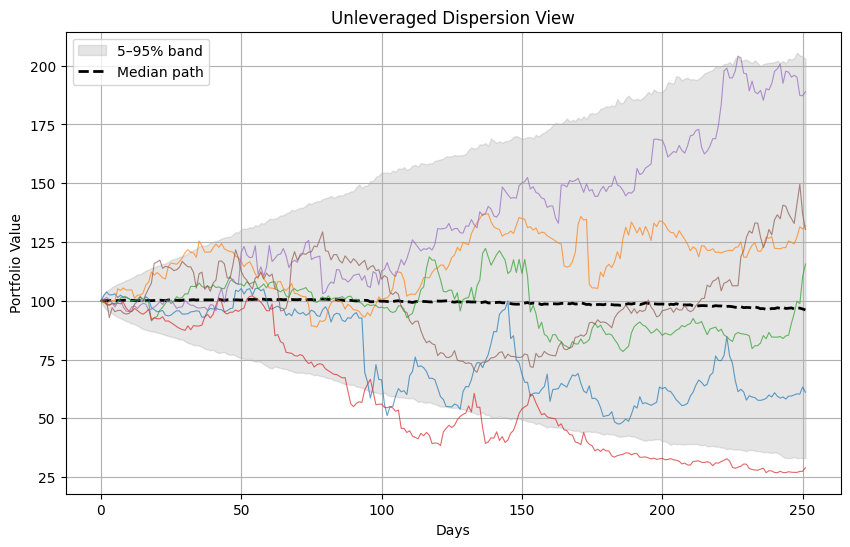

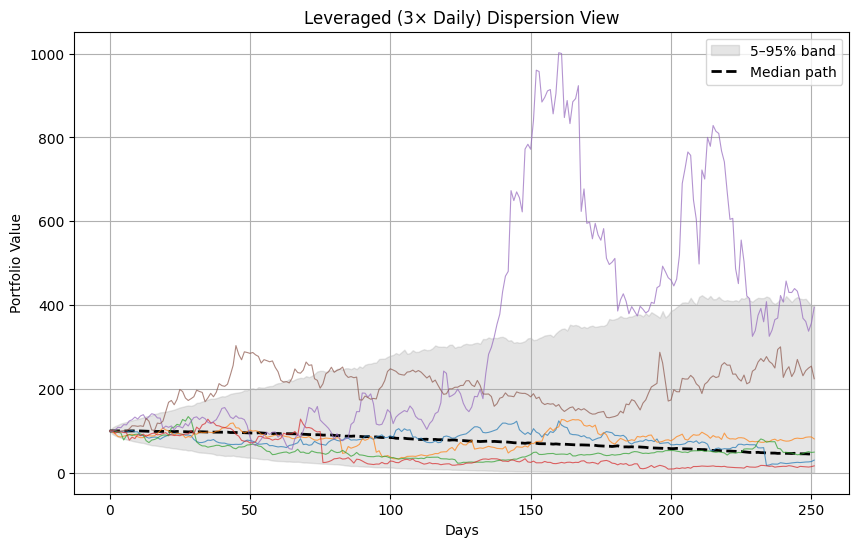

Realized daily vol ≈ 0.0311, annualized ≈ 0.4931


In [ ]:
# --- Example volatility path ---
plt.figure(figsize=(10,4))
plt.plot(sigma[0]*100, color='orange')
plt.title('Example Simulated Volatility Path (GARCH(1,1))')
plt.xlabel('Day'); plt.ylabel('σₜ (%)'); plt.grid(True); plt.show()

# --- Percentile bands & sample paths ---
def plot_with_bands(paths, title, n_samples=6):
    t = np.arange(paths.shape[1])
    p05 = np.percentile(paths, 5, axis=0)
    p50 = np.percentile(paths, 50, axis=0)
    p95 = np.percentile(paths, 95, axis=0)
    plt.figure(figsize=(10,6))
    plt.fill_between(t, p05, p95, color='gray', alpha=0.2, label='5–95% band')
    plt.plot(t, p50, 'k--', lw=2, label='Median path')
    idx = np.random.choice(paths.shape[0], size=min(n_samples, paths.shape[0]), replace=False)
    for i in idx:
        plt.plot(t, paths[i], lw=0.8, alpha=0.7)
    plt.title(title); plt.xlabel('Days'); plt.ylabel('Portfolio Value')
    plt.legend(); plt.grid(True); plt.show()

plot_with_bands(unlev_paths, "Unleveraged Dispersion View")
plot_with_bands(lev_paths,  "Leveraged (3× Daily) Dispersion View")

def realized_vol(paths):
    daily_rets = (paths[:,1:] - paths[:,:-1]) / paths[:,:-1]
    vol_d = np.std(daily_rets, axis=1, ddof=1).mean()
    vol_a = vol_d * np.sqrt(252)
    return vol_d, vol_a

v_d, v_a = realized_vol(unlev_paths)
print(f"Realized daily vol ≈ {v_d:.4f}, annualized ≈ {v_a:.4f}")


## Risk Adjustment Metrics

MDD
Sharpe
Sortino
Calmar

In [ ]:
def calculate_risk_metrics(paths, r_f=0.02):
    """
    Calculate comprehensive performance and risk metrics
    (Sharpe, Sortino, Calmar, Max Drawdown) for simulated price paths.

    Parameters
    ----------
    paths : np.ndarray
        Simulated portfolio values (shape: n_sims x n_days)
    r_f : float
        Annualized risk-free rate.
    """
    initial_price = paths[:, 0]
    final_price = paths[:, -1]
    returns = final_price / initial_price - 1
    daily_returns = np.diff(paths, axis=1) / paths[:, :-1]

    # === Annualized metrics ===
    mean_return = np.mean(returns)
    std_dev = np.std(returns)
    excess = mean_return - r_f

    # Sharpe ratio (annualized)
    sharpe = excess / std_dev if std_dev != 0 else np.nan

    # Sortino ratio (downside deviation only)
    downside = daily_returns[daily_returns < 0]
    downside_std = np.std(downside) * np.sqrt(252)
    sortino = excess / downside_std if downside_std != 0 else np.nan

    # Maximum drawdown
    max_drawdowns = []
    for path in paths:
        peak = np.maximum.accumulate(path)
        drawdown = (path - peak) / peak
        max_drawdowns.append(np.min(drawdown))
    max_dd = np.mean(max_drawdowns)

    # Calmar ratio (return / |max drawdown|)
    calmar = mean_return / abs(max_dd) if max_dd != 0 else np.nan

    return {
        "Mean Return": mean_return,
        "Std Dev": std_dev,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Calmar": calmar,
        "Max Drawdown": max_dd
    }

# --- Example usage: run after Blocks 1–4 ---
metrics_unlev = calculate_risk_metrics(unlev_paths, r_f=0.03)
metrics_lev   = calculate_risk_metrics(lev_paths,   r_f=0.03)

comparison = pd.DataFrame([metrics_unlev, metrics_lev],
                          index=["Unleveraged", "Leveraged 3x"])

print("=== Risk & Performance Metrics ===")
print(comparison.round(4))


=== Risk & Performance Metrics ===
              Mean Return  Std Dev  Sharpe  Sortino  Calmar  Max Drawdown
Unleveraged        0.0619   0.6308  0.0505   0.0762  0.1458       -0.4244
Leveraged 3x       0.3511   5.8466  0.0549   0.2559  0.4359       -0.8054
